Thực hành dò biên:
1. Thực hành các phép phát hiện biên trực tiếp trên ảnh ví dụ 5x5 và 1 ảnh xám văn bản (Hiển thị như nào là tốt nhất)
3. Tự chọn 2-3 ảnh biển số xe. Sử dụng kết hợp phát hiện biên trực tiếp, phân ngưỡng và tìm vùng liên thông để tách riêng phần biển số (và có thể cả chữ số) trên các ảnh đó


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# M, N: kích thước ảnh (rộng, cao)
# m, n: kích thước mẫu (rộng, cao)
# p: điểm chốt
# x, y: điểm được kiểm tra xem có thể đặt mẫu theo chốt không
def co_the_tinh(x, y, M, N, m, n, p):
    x_min = x - p[0]
    y_min = y - p[1]
    x_max = x + m - p[0] - 1
    y_max = y + n - p[1] - 1
    return x_min >= 0 and y_min >= 0 and x_max < M and y_max < N

# p: điểm chốt, mặc định tại (0, 0) - điểm trên cùng bên trái trong mẫu
# inv: giá trị không tính được (thường ký hiệu là *), mặc định giá trị vô cực
def phep_cuon_2(I, T, p=(0, 0), inv=np.inf):
    M, N = I.shape[1], I.shape[0]
    m, n = T.shape[1], T.shape[0]
    I_kq = np.zeros((N, M), np.float32)
    for x in range(I_kq.shape[1]):
        for y in range(I_kq.shape[0]):
            if co_the_tinh(x, y, M, N, m, n, p):
                sum_val = 0.0
                for j in range(n):
                    for i in range(m):
                        sum_val = sum_val + I[y + j - p[1], x + i - p[0]] * T[j, i]
                I_kq[y, x] = sum_val
            else:
                I_kq[y, x] = inv
    return I_kq

## 1. Phát hiện biên trực tiếp trên ảnh 5x5 và ảnh xám văn bản 

In [3]:
# 1. Phép Gradient (Mẫu 1x2 và 2x1, chốt tại (0,0))
# Mẫu 1x2 -> dò sự thay đổi theo phương ngang 
# Mẫu 2x1 dò sự thay đổi theo phương dọc 
def phep_gradient(I):
    A = np.array([[-1, 1]], dtype=np.float32)
    B = np.array([[-1], [1]], dtype=np.float32)
    IxA = phep_cuon_2(I, A)
    IxB = phep_cuon_2(I, B)
    I_kq = IxA + IxB
    return I_kq, IxA, IxB

# 2. Phép Robert (Mẫu chéo 2x2, chốt tại (0,0))
# Đo độ lệch theo 2 phương đường chéo 
# IxHy = I(y + 1, x) - I(y, x + 1) 
def phep_robert(I):
    Hx = np.array([
        [-1, 0],
        [ 0, 1]
    ], dtype=np.float32)
    Hy = np.array([
        [ 0, -1],
        [ 1,  0]
    ], dtype=np.float32)
    IxHx = phep_cuon_2(I, Hx)
    IxHy = phep_cuon_2(I, Hy)
    I_kq = IxHx + IxHy
    return I_kq, IxHx, IxHy

# 3. Phép Prewitt (Mẫu 3x3, đặt tâm tại (1,1) để biên cân đối)
def phep_prewitt(I, p=(1, 1)):
    Hx = np.array([
        [-1, 0, 1],
        [-1, 0, 1],
        [-1, 0, 1],
    ], dtype=np.float32)
    Hy = np.array([
        [-1, -1, -1],
        [ 0,  0,  0],
        [ 1,  1,  1],
    ], dtype=np.float32)
    IxHx = phep_cuon_2(I, Hx, p=p)
    IxHy = phep_cuon_2(I, Hy, p=p)
    I_kq = IxHx + IxHy
    return I_kq, IxHx, IxHy

# 4. Phép Sobel (Mẫu 3x3 nhấn mạnh trọng số ở tâm, chốt tại (1,1))
def phep_sobel(I, p=(1, 1)):
    Hx = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1],
    ], dtype=np.float32)
    Hy = np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1],
    ], dtype=np.float32)
    IxHx = phep_cuon_2(I, Hx, p=p)
    IxHy = phep_cuon_2(I, Hy, p=p)
    I_kq = IxHx + IxHy
    return I_kq, IxHx, IxHy

In [4]:
I_5x5 = np.array([
    [0, 0, 0, 0, 0],
    [0, 8, 8, 8, 0],
    [0, 8, 8, 8, 0],
    [0, 8, 8, 8, 0],
    [0, 0, 0, 0, 0]
], dtype=np.uint8)

print("=== ẢNH BAN ĐẦU 5x5 ===")
print(I_5x5)

for ten_phep, ham_do_bien in [
    ("Gradient", phep_gradient),
    ("Robert", phep_robert),
    ("Prewitt (chốt 0,0)", lambda img: phep_prewitt(img, p=(0,0))),
    ("Sobel (chốt 1,1)", lambda img: phep_sobel(img, p=(1,1)))
]:
    I_kq, IxHx, IxHy = ham_do_bien(I_5x5)
    print(f"\n--- Phép {ten_phep} ---")
    print("I cuộn Hx:\n", IxHx)
    print("I cuộn Hy:\n", IxHy)
    print("Ảnh kết quả (I_kq):\n", I_kq)

=== ẢNH BAN ĐẦU 5x5 ===
[[0 0 0 0 0]
 [0 8 8 8 0]
 [0 8 8 8 0]
 [0 8 8 8 0]
 [0 0 0 0 0]]

--- Phép Gradient ---
I cuộn Hx:
 [[ 0.  0.  0.  0. inf]
 [ 8.  0.  0. -8. inf]
 [ 8.  0.  0. -8. inf]
 [ 8.  0.  0. -8. inf]
 [ 0.  0.  0.  0. inf]]
I cuộn Hy:
 [[ 0.  8.  8.  8.  0.]
 [ 0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.]
 [ 0. -8. -8. -8.  0.]
 [inf inf inf inf inf]]
Ảnh kết quả (I_kq):
 [[  0.   8.   8.   8.  inf]
 [  8.   0.   0.  -8.  inf]
 [  8.   0.   0.  -8.  inf]
 [  8.  -8.  -8. -16.  inf]
 [ inf  inf  inf  inf  inf]]

--- Phép Robert ---
I cuộn Hx:
 [[ 8.  8.  8.  0. inf]
 [ 8.  0.  0. -8. inf]
 [ 8.  0.  0. -8. inf]
 [ 0. -8. -8. -8. inf]
 [inf inf inf inf inf]]
I cuộn Hy:
 [[ 0.  8.  8.  8. inf]
 [-8.  0.  0.  8. inf]
 [-8.  0.  0.  8. inf]
 [-8. -8. -8.  0. inf]
 [inf inf inf inf inf]]
Ảnh kết quả (I_kq):
 [[  8.  16.  16.   8.  inf]
 [  0.   0.   0.   0.  inf]
 [  0.   0.   0.   0.  inf]
 [ -8. -16. -16.  -8.  inf]
 [ inf  inf  inf  inf  inf]]

--- Phép Prewitt (chốt 0,0) -

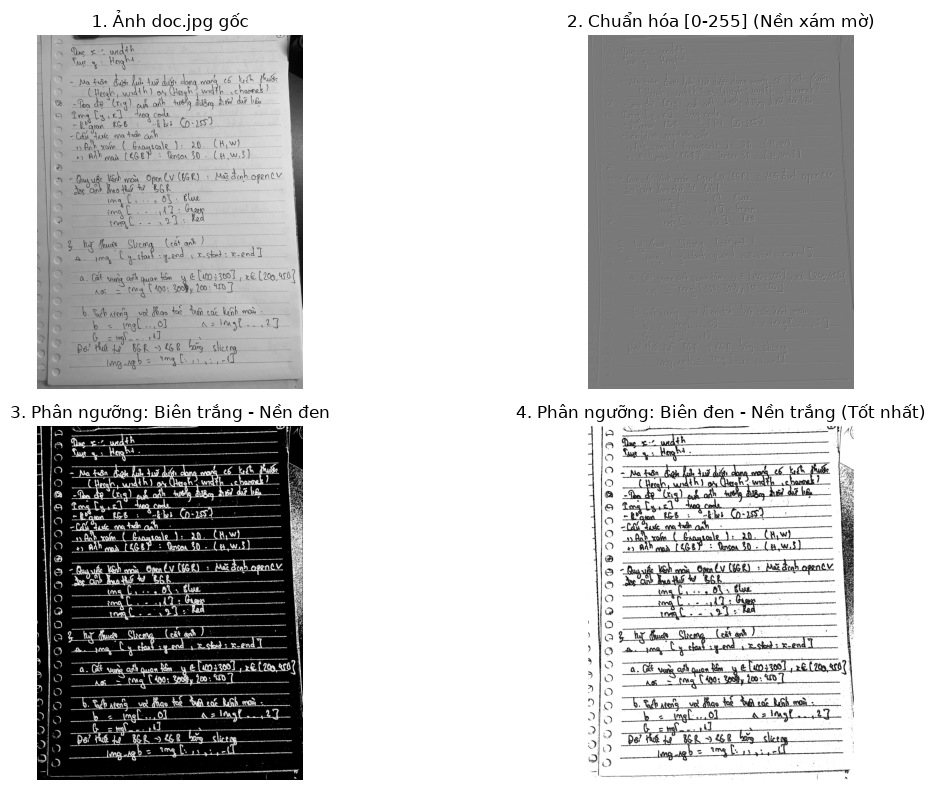

In [5]:
anh_van_ban = cv2.imread("doc.jpg", cv2.IMREAD_GRAYSCALE)
def sinh_anh_hien_thi_bien(I_e, theta, nen_trang=False):
    I_kq = np.zeros(I_e.shape, np.uint8)
    for i in range(I_e.shape[0]):
        for j in range(I_e.shape[1]):
            # Bỏ qua các điểm biên có giá trị vô cực (np.inf)
            la_bien = (not np.isinf(I_e[i, j])) and (abs(I_e[i, j]) > theta)
            if nen_trang:
                I_kq[i, j] = 0 if la_bien else 255  # Biên đen (0), nền trắng (255)
            else:
                I_kq[i, j] = 255 if la_bien else 0  # Biên trắng (255), nền đen (0)
    return I_kq

    
# 2. Thực hành dò biên và so sánh cách hiển thị trên ảnh văn bản doc.jpg
I_kq_vb, IxHx_vb, IxHy_vb = phep_sobel(anh_van_ban, p=(1, 1))

# Kết hợp biên theo tổng trị tuyệt đối |IxHx| + |IxHy| (loại bỏ np.inf ở viền)
IxHx_sach = np.where(np.isinf(IxHx_vb), 0, IxHx_vb)
IxHy_sach = np.where(np.isinf(IxHy_vb), 0, IxHy_vb)
I_bien_tong_hop = np.abs(IxHx_sach) + np.abs(IxHy_sach)

# Tự động chọn ngưỡng theta dựa theo phân vị mức biên của ảnh doc.jpg
nguong_vb = np.percentile(I_bien_tong_hop, 85)

# 3 phương pháp hiển thị
I_tam = np.where(np.isinf(I_kq_vb), 0, I_kq_vb)
I_view_chuan_hoa = cv2.normalize(I_tam, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
I_view_nen_den = sinh_anh_hien_thi_bien(I_bien_tong_hop, theta=nguong_vb, nen_trang=False)
I_view_nen_trang = sinh_anh_hien_thi_bien(I_bien_tong_hop, theta=nguong_vb, nen_trang=True)

plt.figure(figsize=(14, 8))
plt.subplot(2, 2, 1); plt.imshow(anh_van_ban, cmap='gray'); plt.title("1. Ảnh doc.jpg gốc"); plt.axis("off")
plt.subplot(2, 2, 3); plt.imshow(I_view_nen_den, cmap='gray'); plt.title("3. Phân ngưỡng: Biên trắng - Nền đen"); plt.axis("off")
plt.subplot(2, 2, 4); plt.imshow(I_view_nen_trang, cmap='gray'); plt.title("4. Phân ngưỡng: Biên đen - Nền trắng (Tốt nhất)"); plt.axis("off")
plt.tight_layout()
plt.show()

## Tách biển số xe và chữ số kết hợp Dò biên, phân ngưỡng và tìm vùng liên thông 

In [19]:
def sinh_anh_hien_thi_bien(I_e, theta):
    I_kq = np.zeros(I_e.shape, np.uint8)
    for i in range(I_e.shape[0]):
        for j in range(I_e.shape[1]):
            # Nếu tính được (khác vô cực) và độ lệch lớn hơn ngưỡng theta -> Điểm biên (255)
            if I_e[i, j] != np.inf and abs(I_e[i, j]) > theta:
                I_kq[i, j] = 255
            else:
                I_kq[i, j] = 0
    return I_kq

In [20]:
def tim_vung_lien_thong(I_nhi_phan, ban_kinh=2):
    N, M = I_nhi_phan.shape
    da_xet = np.zeros((N, M), dtype=np.uint8) # 0: chưa xét, 1: đã xét
    cac_khung_bao = [] # Lưu danh sách các khung (x_min, y_min, x_max, y_max)

    for y in range(N):
        for x in range(M):
            # Gặp điểm trắng (255) chưa được xét -> Bắt đầu loang để gom vùng
            if I_nhi_phan[y, x] == 255 and da_xet[y, x] == 0:
                ds_cho = [(x, y)]
                da_xet[y, x] = 1
                x_min, x_max = x, x
                y_min, y_max = y, y

                while len(ds_cho) > 0:
                    cx, cy = ds_cho.pop()
                    # Cập nhật 4 cạnh của khung chữ nhật bao quanh vùng
                    if cx < x_min: x_min = cx
                    if cx > x_max: x_max = cx
                    if cy < y_min: y_min = cy
                    if cy > y_max: y_max = cy

                    # Kiểm tra các điểm xung quanh trong phạm vi ban_kinh
                    for ny in range(max(0, cy - ban_kinh), min(N, cy + ban_kinh + 1)):
                        for nx in range(max(0, cx - ban_kinh), min(M, cx + ban_kinh + 1)):
                            if I_nhi_phan[ny, nx] == 255 and da_xet[ny, nx] == 0:
                                da_xet[ny, nx] = 1
                                ds_cho.append((nx, ny))

                cac_khung_bao.append((x_min, y_min, x_max, y_max))
    return cac_khung_bao

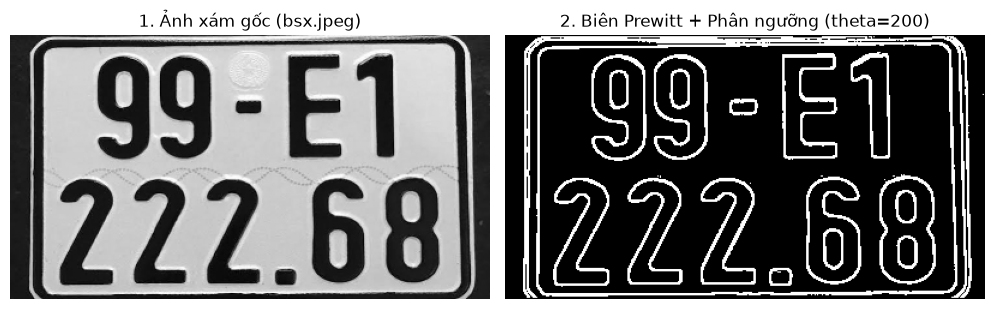

In [31]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def co_the_tinh(x, y, M, N, m, n, p):
    x_min = x - p[0]
    y_min = y - p[1]
    x_max = x + m - p[0] - 1
    y_max = y + n - p[1] - 1
    return x_min >= 0 and y_min >= 0 and x_max < M and y_max < N

def phep_cuon_2(I, T, p=(0, 0), inv=np.inf):
    M, N = I.shape[1], I.shape[0]
    m, n = T.shape[1], T.shape[0]
    I_kq = np.zeros((N, M), np.float32)
    for x in range(M):
        for y in range(N):
            if co_the_tinh(x, y, M, N, m, n, p):
                s = 0.0
                for j in range(n):
                    for i in range(m):
                        s = s + I[y + j - p[1], x + i - p[0]] * T[j, i]
                I_kq[y, x] = s
            else:
                I_kq[y, x] = inv
    return I_kq

def phep_prewitt(I):
    Hx = np.array([
        [-1, 0, 1],
        [-1, 0, 1],
        [-1, 0, 1]
    ], dtype=np.float32)
    Hy = np.array([
        [-1, -1, -1],
        [ 0,  0,  0],
        [ 1,  1,  1]
    ], dtype=np.float32)
    IxHx = phep_cuon_2(I, Hx, p=(1, 1))
    IxHy = phep_cuon_2(I, Hy, p=(1, 1))
    # Lấy tổng trị tuyệt đối để giữ đủ cả biên dọc (Hx) và biên ngang (Hy)
    I_kq = np.abs(IxHx) + np.abs(IxHy)
    return I_kq, IxHx, IxHy

# ==========================================
# BƯỚC 2: PHÂN NGƯỠNG HIỂN THỊ BIÊN (CÁCH 4)
# ==========================================
def sinh_anh_hien_thi_bien(I_e, theta):
    I_kq = np.zeros(I_e.shape, np.uint8)
    for i in range(I_e.shape[0]):
        for j in range(I_e.shape[1]):
            # Nếu tính được (khác vô cực) và độ lệch lớn hơn ngưỡng theta -> Điểm biên (255)
            if I_e[i, j] != np.inf and abs(I_e[i, j]) > theta:
                I_kq[i, j] = 255
            else:
                I_kq[i, j] = 0
    return I_kq
    

I_bsx = cv2.imread("bsx.jpeg", cv2.IMREAD_GRAYSCALE)
I_bsx = cv2.resize(I_bsx, (400, 220))
N, M = I_bsx.shape

# 2. Dò biên Prewitt và Phân ngưỡng với theta = 200
I_bien, _, _ = phep_prewitt(I_bsx)
I_nhi_phan = sinh_anh_hien_thi_bien(I_bien, theta=200)

# 3. Tìm tất cả các vùng liên thông trên ảnh biên nhị phân
tat_ca_vung = tim_vung_lien_thong(I_nhi_phan, ban_kinh=2)

# 4. Phân loại vùng nào là Khung biển số, vùng nào là Chữ số
khung_bien_so = None
ds_chu_so = []

for (x1, y1, x2, y2) in tat_ca_vung:
    rong = x2 - x1 + 1
    cao = y2 - y1 + 1

    # Khung biển số là vùng bao lớn nhất (rộng > 70% ảnh, cao > 70% ảnh)
    if rong > 0.7 * M and cao > 0.7 * N:
        khung_bien_so = (x1, y1, x2, y2)

    # Chữ số có chiều cao khoảng 25% -> 55% chiều cao biển, rộng từ 4% -> 25% chiều rộng biển
    elif (0.25 * N <= cao <= 0.55 * N) and (0.04 * M <= rong <= 0.25 * M):
        ds_chu_so.append((x1, y1, x2, y2))

# 5. Vẽ khung kết quả lên ảnh để hiển thị
I_ket_qua = cv2.cvtColor(I_bsx, cv2.COLOR_GRAY2RGB)

# Hiển thị 3 bước trực quan
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1); plt.imshow(I_bsx, cmap='gray'); plt.title("1. Ảnh xám gốc (bsx.jpeg)"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(I_nhi_phan, cmap='gray'); plt.title("2. Biên Prewitt + Phân ngưỡng (theta=200)"); plt.axis("off")
plt.tight_layout()
plt.show()